## Experiment: visualize the likelihood of a Bernoulli success probability.

MLE p_hat = 0.35
Likelihood at p_hat = 0.184401


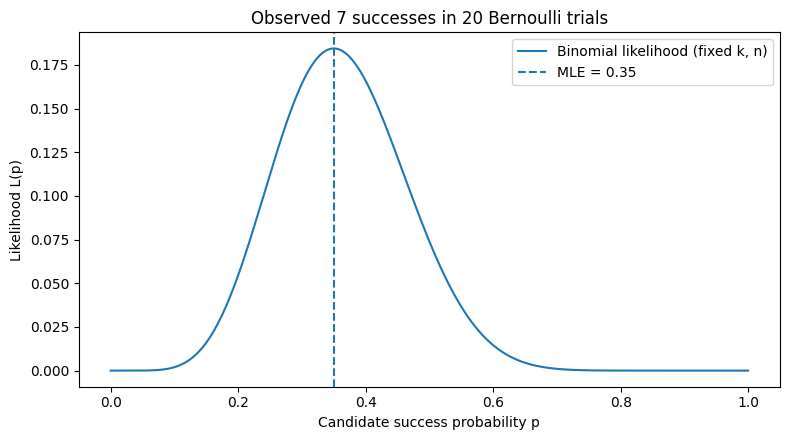

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

n, k = 20, 7
p_grid = np.linspace(0, 1, 501)
likelihood = binom.pmf(k, n, p_grid)
p_hat = k / n

print("MLE p_hat =", p_hat)
print("Likelihood at p_hat =", round(binom.pmf(k, n, p_hat), 6))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(p_grid, likelihood, label="Binomial likelihood (fixed k, n)")
ax.axvline(p_hat, linestyle="--", label=f"MLE = {p_hat:.2f}")
ax.set(xlabel="Candidate success probability p", ylabel="Likelihood L(p)",
       title=f"Observed {k} successes in {n} Bernoulli trials")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/mle_binomial_likelihood.png", dpi=170, bbox_inches="tight")
plt.show()

## Experiment: estimate a Poisson arrival rate analytically and numerically.

In [3]:
import numpy as np
from scipy.optimize import minimize_scalar
from scipy.stats import poisson

counts = np.array([1, 0, 3, 2, 4, 1, 2, 3, 0, 2], dtype=int)
lam_hat = counts.mean()

def nll(lam):
    return -np.sum(poisson.logpmf(counts, mu=lam))

result = minimize_scalar(nll, bounds=(0.001, 10), method="bounded")
print("Analytic MLE:", round(lam_hat, 6))
print("Numerical MLE:", round(result.x, 6))
print("Numerical optimization succeeded:", result.success)
print("Difference:", round(result.x - lam_hat, 8))

Analytic MLE: 1.8
Numerical MLE: 1.8
Numerical optimization succeeded: True
Difference: -3e-08


## Experiment: compare normal variance MLE and unbiased sample variance.

MLE mean: 3.4972 bias: -0.5028 MSE: 3.6787
Unbiased mean: 3.9968 bias: -0.0032 MSE: 4.4746
Theoretical E[MLE]: 3.5


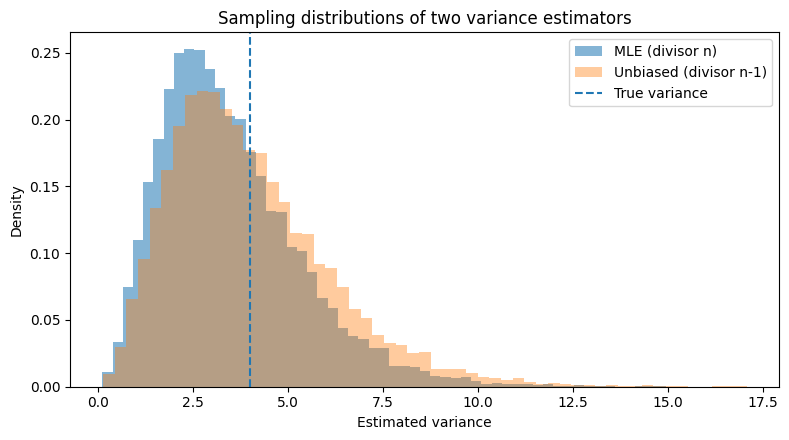

In [4]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(145)
n, repetitions, sigma = 8, 12000, 2.0
samples = rng.normal(3.0, sigma, size=(repetitions, n))
v_mle = np.var(samples, axis=1, ddof=0)
v_unbiased = np.var(samples, axis=1, ddof=1)
truth = sigma**2
for name, estimates in [("MLE", v_mle), ("Unbiased", v_unbiased)]:
    print(name, "mean:", round(estimates.mean(), 4),
          "bias:", round(np.mean(estimates - truth), 4),
          "MSE:", round(np.mean((estimates - truth)**2), 4))
print("Theoretical E[MLE]:", (n-1)/n * truth)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(v_mle, bins=55, density=True, alpha=0.55, label="MLE (divisor n)")
ax.hist(v_unbiased, bins=55, density=True, alpha=0.4,
        label="Unbiased (divisor n-1)")
ax.axvline(truth, linestyle="--", label="True variance")
ax.set(xlabel="Estimated variance", ylabel="Density",
       title="Sampling distributions of two variance estimators")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/mle_normal_variance_bias.png", dpi=170, bbox_inches="tight")
plt.show()

## Experiment: estimate exponential rate and mean lifetime.

Mean estimated rate: 0.4349
Expected rate MLE: 0.4364
Mean estimated lifetime: 2.5038


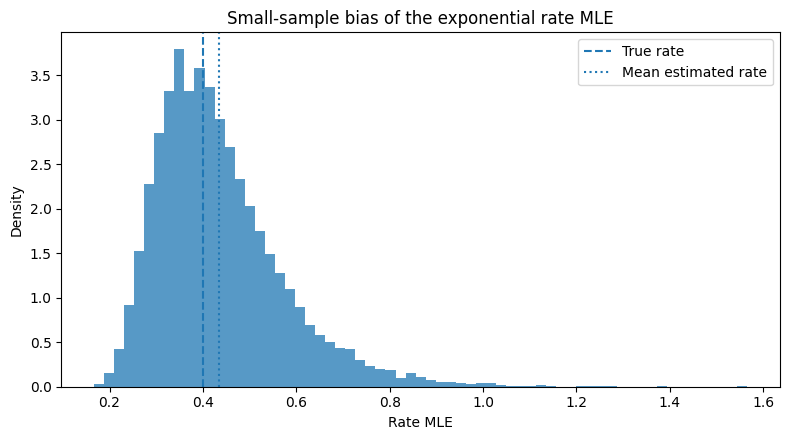

In [5]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(146)
rate_true, n, repetitions = 0.4, 12, 10000
samples = rng.exponential(scale=1 / rate_true, size=(repetitions, n))
rate_hat = 1 / samples.mean(axis=1)
mean_lifetime_hat = samples.mean(axis=1)
print("Mean estimated rate:", round(rate_hat.mean(), 4))
print("Expected rate MLE:", round(n*rate_true/(n-1), 4))
print("Mean estimated lifetime:", round(mean_lifetime_hat.mean(), 4))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(rate_hat, bins=65, density=True, alpha=0.75)
ax.axvline(rate_true, linestyle="--", label="True rate")
ax.axvline(rate_hat.mean(), linestyle=":", label="Mean estimated rate")
ax.set(xlabel="Rate MLE", ylabel="Density", title="Small-sample bias of the exponential rate MLE")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/mle_exponential_rate_bias.png", dpi=170, bbox_inches="tight")
plt.show()

## Experiment: show a boundary MLE in a uniform model.

Sample maximum (MLE): 4.9474
Bias-corrected estimate: 5.2773


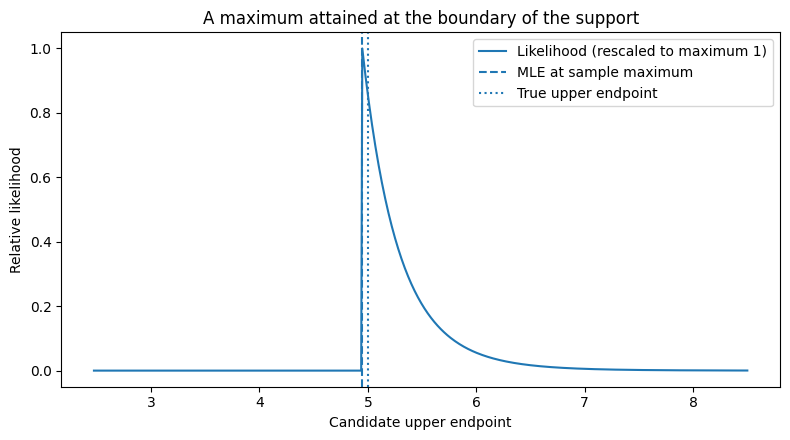

In [6]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(147)
theta_true, n = 5.0, 15
x = rng.uniform(0, theta_true, size=n)
x_max = max(x)
theta_grid = np.linspace(0.5*x_max, 1.7*theta_true, 600)
likelihood = np.where(theta_grid >= x_max, theta_grid**(-n), 0.0)
likelihood /= likelihood.max()

print("Sample maximum (MLE):", round(x_max, 4))
print("Bias-corrected estimate:", round((n+1)/n*x_max, 4))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(theta_grid, likelihood, label="Likelihood (rescaled to maximum 1)")
ax.axvline(x_max, linestyle="--", label="MLE at sample maximum")
ax.axvline(theta_true, linestyle=":", label="True upper endpoint")
ax.set(xlabel="Candidate upper endpoint", ylabel="Relative likelihood",
       title="A maximum attained at the boundary of the support")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/mle_uniform_boundary.png", dpi=170, bbox_inches="tight")
plt.show()

## Experiment: check Fisher-information standard errors by simulation.

n=20: empirical SE=0.10614; theory=0.10665
n=80: empirical SE=0.05353; theory=0.05333
n=320: empirical SE=0.02654; theory=0.02666


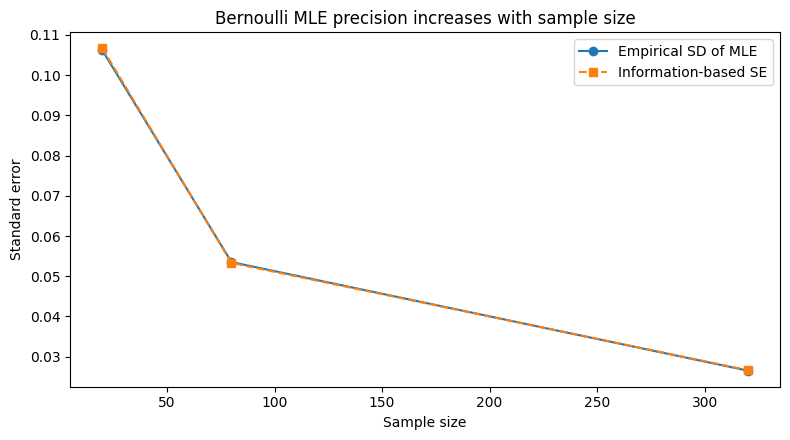

In [7]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(148)
p_true, repetitions = 0.35, 5000
sample_sizes = [20, 80, 320]
empirical = []
theoretical = []
for n in sample_sizes:
    estimates = rng.binomial(n, p_true, size=repetitions) / n
    empirical.append(estimates.std(ddof=1))
    theoretical.append(np.sqrt(p_true*(1-p_true)/n))
    print(f"n={n}: empirical SE={empirical[-1]:.5f}; theory={theoretical[-1]:.5f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sample_sizes, empirical, "o-", label="Empirical SD of MLE")
ax.plot(sample_sizes, theoretical, "s--", label="Information-based SE")
ax.set(xlabel="Sample size", ylabel="Standard error",
       title="Bernoulli MLE precision increases with sample size")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/mle_fisher_information.png", dpi=170, bbox_inches="tight")
plt.show()

## Experiment: estimate a two-parameter normal model by numerical optimization.

In [9]:
import numpy as np
from scipy.optimize import minimize

rng = np.random.default_rng(149)
x = rng.normal(loc=2.3, scale=1.7, size=90)

# Parameterization: theta = (mu, log_sigma) guarantees sigma > 0.
def nll(theta):
    mu, log_sigma = theta
    sigma = np.exp(log_sigma)
    return (len(x) * (0.5*np.log(2*np.pi) + log_sigma)
            + np.sum((x-mu)**2) / (2*sigma**2))

def gradient(theta):
    mu, log_sigma = theta
    variance = np.exp(2*log_sigma)
    sum_sq = np.sum((x-mu)**2)
    return np.array([np.sum(mu-x)/variance,
                     len(x) - sum_sq/variance])

result = minimize(nll, x0=np.array([0.0, 0.0]), jac=gradient,
                  method="BFGS", options={"gtol": 1e-7})
mu_mle, sigma_mle = x.mean(), x.std(ddof=0)
print("Analytic MLE (mu, sigma):", np.round([mu_mle, sigma_mle], 5))
print("Numerical MLE (mu, sigma):",
      np.round([result.x[0], np.exp(result.x[1])], 5))
print("Gradient norm:", round(np.linalg.norm(result.jac), 7))
print("Optimizer message:", result.message)

Analytic MLE (mu, sigma): [2.35439 1.61057]
Numerical MLE (mu, sigma): [2.35439 1.61057]
Gradient norm: 0.0
Optimizer message: Optimization terminated successfully.


## Experiment: verify Gaussian squared error and Bernoulli cross-entropy.

In [11]:
import numpy as np
from scipy.stats import norm
from scipy.special import expit, xlogy

x = np.array([-1., 0., 1., 2.])
y_real = np.array([-0.5, 1.3, 2.7, 4.1])
mu = 0.9 + 1.5*x
sigma = 1.4
normal_nll = -np.sum(norm.logpdf(y_real, loc=mu, scale=sigma))
squared_error = np.sum((y_real - mu)**2)
constant = len(x) * (0.5*np.log(2*np.pi) + np.log(sigma))
print("Gaussian NLL minus constant:", round(normal_nll - constant, 5))

y_binary = np.array([0, 0, 1, 1])
p = expit(-0.4 + 1.2*x)
# xlogy handles zero-weighted log terms without producing NaN.
bernoulli_nll = -np.sum(xlogy(y_binary, p)
                         + xlogy(1-y_binary, 1-p))
print("Gaussian NLL:", round(normal_nll, 5))
print("SSE scaled by 1/(2*sigma^2):", round(squared_error/(2*sigma**2), 5))
print("Bernoulli NLL (total log loss):", round(bernoulli_nll, 5))
print("Bernoulli mean log loss:", round(bernoulli_nll/len(y_binary), 5))

Gaussian NLL minus constant: 0.07653
Gaussian NLL: 5.09817
SSE scaled by 1/(2*sigma^2): 0.07653
Bernoulli NLL (total log loss): 1.19494
Bernoulli mean log loss: 0.29874


##  Experiment: compare Bernoulli MLE, MAP, and the posterior distribution.

MLE: 0.0833 MAP: 0.1875 Posterior mean: 0.2222


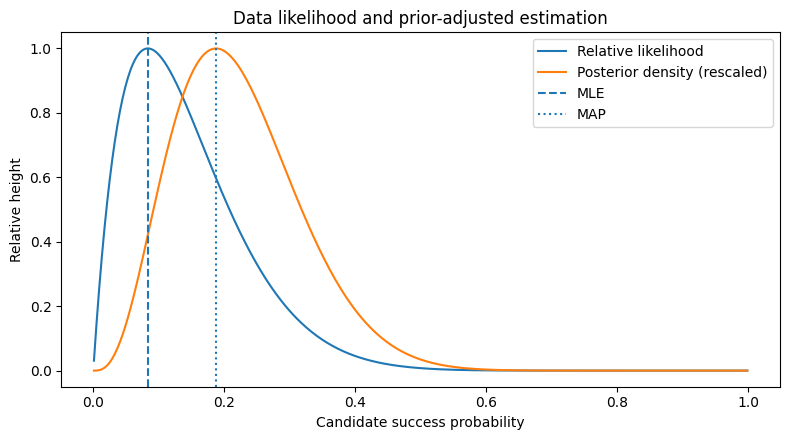

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta, binom

n, k = 12, 1
a, b = 3, 3
p_mle = k/n
p_map = (k+a-1)/(n+a+b-2)
p_mean = (k+a)/(n+a+b)
grid = np.linspace(0.001, 0.999, 500)
likelihood = binom.pmf(k, n, grid)
posterior = beta.pdf(grid, k+a, n-k+b)

print("MLE:", round(p_mle, 4), "MAP:", round(p_map, 4),
      "Posterior mean:", round(p_mean, 4))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(grid, likelihood/likelihood.max(), label="Relative likelihood")
ax.plot(grid, posterior/posterior.max(), label="Posterior density (rescaled)")
ax.axvline(p_mle, linestyle="--", label="MLE")
ax.axvline(p_map, linestyle=":", label="MAP")
ax.set(xlabel="Candidate success probability", ylabel="Relative height",
       title="Data likelihood and prior-adjusted estimation")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/mle_vs_map.png", dpi=170, bbox_inches="tight")
plt.show()

## Experiment: construct a profile-likelihood confidence interval for Bernoulli p.

MLE: 0.2
Approximate LR interval: (0.0968, 0.3404)
Approximate Wald interval: (0.076, 0.324)


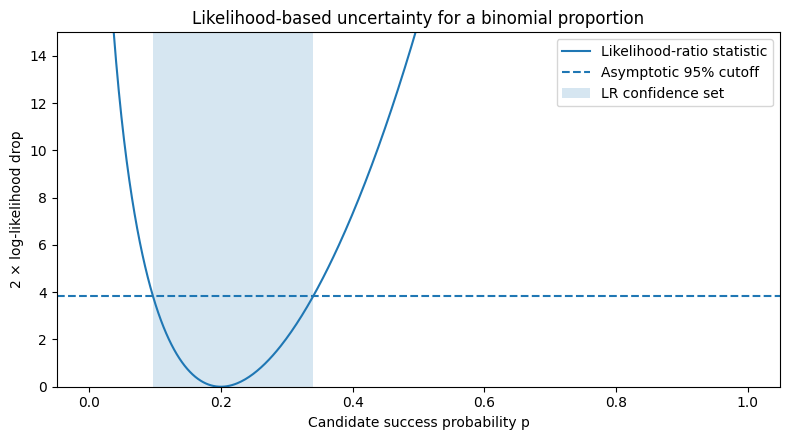

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import xlogy
from scipy.optimize import brentq
from scipy.stats import chi2, norm

n, k, alpha = 40, 8, 0.05
p_hat = k/n

def loglik(p):
    if p < 0 or p > 1:
        return -np.inf
    return xlogy(k, p) + xlogy(n-k, 1-p)

cutoff = chi2.ppf(1-alpha, df=1)
def lr_stat(p):
    return 2*(loglik(p_hat) - loglik(p))

lower = 0 if k == 0 else brentq(lambda p: lr_stat(p)-cutoff, 0, p_hat)
upper = 1 if k == n else brentq(lambda p: lr_stat(p)-cutoff, p_hat, 1)
wald_se = np.sqrt(p_hat*(1-p_hat)/n)
wald_low = p_hat - norm.ppf(1-alpha/2)*wald_se
wald_high = p_hat + norm.ppf(1-alpha/2)*wald_se
print("MLE:", p_hat)
print("Approximate LR interval:", tuple(round(v, 4) for v in (lower, upper)))
print("Approximate Wald interval:", tuple(round(v, 4) for v in (wald_low, wald_high)))

p_grid = np.linspace(0.001, 0.999, 500)
values = np.array([lr_stat(p) for p in p_grid])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(p_grid, values, label="Likelihood-ratio statistic")
ax.axhline(cutoff, linestyle="--", label="Asymptotic 95% cutoff")
ax.axvspan(lower, upper, alpha=0.18, label="LR confidence set")
ax.set(xlabel="Candidate success probability p", ylabel="2 × log-likelihood drop",
       ylim=(0, 15), title="Likelihood-based uncertainty for a binomial proportion")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/mle_likelihood_ratio_interval.png", dpi=170,
            bbox_inches="tight")
plt.show()